# Principle and applications of BPCS-Steganography

Implementacja algorytmu z artykułu *Principle and applications of BPCS-Steganography* (Kawaguchi, Eason, 1998).

## 1. Overview

**Idea.** Człowiek nie widzi żadnego kształtu w bardzo złożonych, „szumopodobnych" wzorach binarnych. Obraz-nośnik (*vessel*) rozkładamy więc na płaszczyzny bitowe i **zastępujemy wszystkie szumopodobne fragmenty tajnymi danymi** — obraz wygląda tak samo, a pojemność sięga ok. 50% jego rozmiaru (tradycyjne metody: 5–15%).

**Algorytm osadzania:**
1. Obraz RGB przekształcamy z naturalnego kodu binarnego (PBC) na kod Graya (CGC) i dzielimy na 24 płaszczyzny bitowe (3 kanały × 8 bitów).
2. Każdą płaszczyznę dzielimy na bloki 8×8 i liczymy ich złożoność $\alpha = k / k_{max}$, gdzie $k$ to długość granicy czarno-białej, a $k_{max}=112$.
3. Bloki z $\alpha \ge \alpha_0$ (typowo $\alpha_0 = 0.3$) uznajemy za szumopodobne — to w nich ukrywamy dane.
4. Tajny plik dzielimy na bloki po 8 bajtów (= 64 bity = blok 8×8). Zbyt prosty blok ($\alpha < \alpha_0$) **sprzęgamy**: $P^* = P \oplus W_c$ ($W_c$ – szachownica), co daje $\alpha(P^*) = 1 - \alpha(P)$. Informację o sprzężeniu zapisujemy w *conjugation map*.
5. Bloki szumopodobne zastępujemy blokami tajnych danych (oraz mapą sprzężeń) i wracamy z CGC do PBC.

Odczyt to odwrotność tych kroków. Dodatkowo, zgodnie z sekcją *Customization* artykułu, nagłówek i mapa są „wybielane" strumieniem pseudolosowym, a kolejność bloków zależy od klucza.

## 2. Przygotowanie danych

Używamy czterech obrazów RGB (`uint8`): sztucznej szachownicy oraz trzech zdjęć z `scikit-image`. Szachownica to celowo **zły nośnik** - składa się z dużych płaskich pól, więc nie ma w niej szumopodobnych bloków. Wymiary niepodzielne przez 8 (np. `cat`) obsługujemy, używając tylko pełnych bloków.

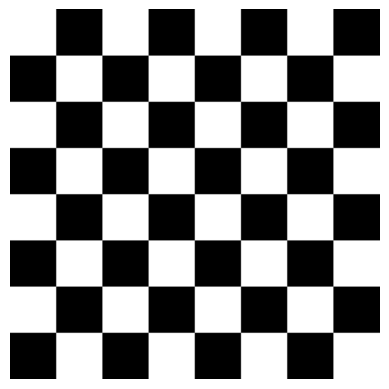

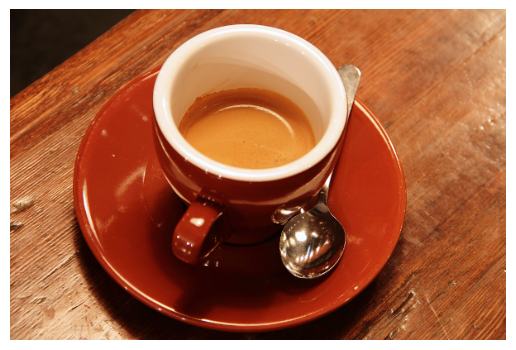

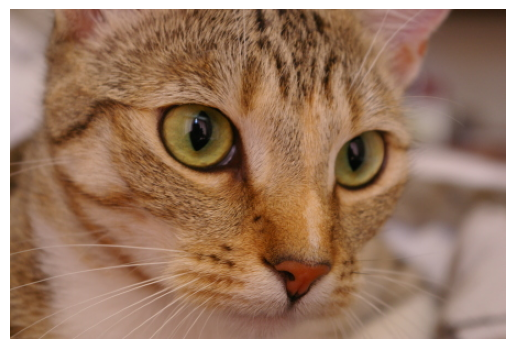

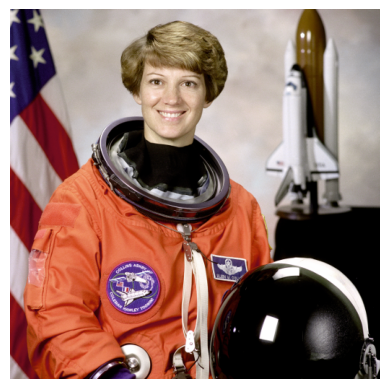

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import data

checkerboard = (data.checkerboard() > 127).astype(np.uint8) * 255
checkerboard = np.repeat(checkerboard[..., np.newaxis], 3, axis=-1)

imgs_color = [checkerboard, data.coffee(), data.cat(), data.astronaut()]
image_names = ["checkerboard", "coffee", "cat", "astronaut"]

for img in imgs_color:
    plt.imshow(img)
    plt.axis('off')
    plt.show()

## 3. Implementacja

### 3.1 Kod Graya i płaszczyzny bitowe

W naturalnym kodzie binarnym mała zmiana jasności może odwrócić wiele bitów naraz (np. `01111111` → `10000000`, tzw. *Hamming cliffs*), przez co płaskie obszary wyglądają na złożone. W kodzie Graya, `g = b ^ (b >> 1)`, sąsiednie wartości różnią się jednym bitem, więc złożoność płaszczyzn lepiej odpowiada rzeczywistej zmienności obrazu.

In [8]:
BLOCK = 8
MAX_BORDER = 2 * BLOCK * (BLOCK - 1)   # 112 = maks. liczba zmian B-W w bloku 8x8


def pbc_to_cgc(img):
    """Pure Binary Code -> Canonical Gray Code (element po elemencie)."""
    return img ^ (img >> 1)


def cgc_to_pbc(g):
    """Canonical Gray Code -> Pure Binary Code."""
    b = g.copy()
    for shift in (1, 2, 4):
        b ^= b >> shift
    return b


def to_planes(img):
    """Obraz RGB (H, W, 3) -> płaszczyzny bitowe CGC (24, H8, W8); H8, W8 to wymiary przycięte do wielokrotności 8."""
    h, w = img.shape[0] // BLOCK * BLOCK, img.shape[1] // BLOCK * BLOCK
    g = pbc_to_cgc(img[:h, :w])
    bits = (g[..., None] >> np.arange(8)) & 1                       # (h, w, 3, 8)
    return bits.transpose(2, 3, 0, 1).reshape(24, h, w).astype(np.uint8)


def from_planes(planes, img):
    """Odwrotność to_planes; część obrazu poza pełnymi blokami kopiujemy z oryginału."""
    _, h, w = planes.shape
    weights = (1 << np.arange(8)).astype(np.uint8)[None, :, None, None]
    g = (planes.reshape(3, 8, h, w) * weights).sum(axis=1, dtype=np.uint8)   # (3, h, w)
    out = img.copy()
    out[:h, :w] = cgc_to_pbc(g.transpose(1, 2, 0))
    return out


x = np.arange(256, dtype=np.uint8)
assert (cgc_to_pbc(pbc_to_cgc(x)) == x).all()
assert (from_planes(to_planes(imgs_color[1]), imgs_color[1]) == imgs_color[1]).all()

### 3.2 Złożoność i sprzężenie bloków

Złożoność bloku to liczba zmian kolor-czarny/biały wzdłuż wierszy i kolumn podzielona przez maksimum (112):

$$\alpha = \frac{k}{k_{max}}, \qquad 0 \le \alpha \le 1.$$

Sprzężenie $P^* = P \oplus W_c$ odwraca każdą zmianę na granicy pikseli, więc $\alpha(P^*) = 1-\alpha(P)$ i $(P^*)^* = P$. Dzięki temu każdy zbyt prosty blok tajnych danych można zamienić na szumopodobny i później odtworzyć.

In [9]:
WC = (np.indices((BLOCK, BLOCK)).sum(axis=0) % 2).astype(np.uint8)   # szachownica Wc (0 w lewym górnym rogu)


def to_blocks(planes):
    """(P, H, W) -> widok (P, H/8, W/8, 8, 8)."""
    P, h, w = planes.shape
    return planes.reshape(P, h // BLOCK, BLOCK, w // BLOCK, BLOCK).transpose(0, 1, 3, 2, 4)


def from_blocks(blocks):
    P, hb, wb = blocks.shape[:3]
    return blocks.transpose(0, 1, 3, 2, 4).reshape(P, hb * BLOCK, wb * BLOCK)


def complexity(b):
    """Złożoność alfa bloków; działa na tablicach o kształcie (..., 8, 8)."""
    k = (b[..., 1:] != b[..., :-1]).sum(axis=(-1, -2)) + (b[..., 1:, :] != b[..., :-1, :]).sum(axis=(-1, -2))
    return k / MAX_BORDER


def conjugate(b):
    return b ^ WC


p = np.random.default_rng(0).integers(0, 2, (BLOCK, BLOCK), dtype=np.uint8)
assert np.isclose(complexity(conjugate(p)), 1 - complexity(p))
assert (conjugate(conjugate(p)) == p).all()

### 3.3 Osadzanie

Strumień bloków wstawianych do obrazu ma postać: **[nagłówek] [bloki danych] [mapa sprzężeń]**.

- nagłówek – długość tajnych danych (8 bajtów = jeden blok),
- bloki danych – po 8 bajtów, sprzężone, jeśli $\alpha < \alpha_0$,
- mapa sprzężeń – 1 bit na blok danych (64 bity = 1 blok); jest „wybielana" strumieniem pseudolosowym z klucza, żeby sama była szumopodobna.

Bloki są wstawiane w szumopodobne miejsca obrazu: od najmniej znaczących płaszczyzn bitowych ku najbardziej znaczącym, a w obrębie jednej warstwy w kolejności wyznaczonej przez klucz. (To nasze rozszerzenie — artykuł nie określa kolejności — dzięki któremu przy niepełnym zapełnieniu zmiany trafiają w najmniej widoczne bity.) Ponieważ wstawiane bloki zawsze mają $\alpha \ge \alpha_0$, zbiór szumopodobnych miejsc po osadzeniu jest taki sam jak przed — dzięki temu dekoder znajdzie te same pozycje.

In [10]:
import struct


def bytes_to_blocks(data):
    """Bajty -> bloki 8x8 bitów (8 bajtów na blok, dopełnienie zerami)."""
    data = data + bytes(-len(data) % 8)
    return np.unpackbits(np.frombuffer(data, np.uint8)).reshape(-1, BLOCK, BLOCK)


def blocks_to_bytes(blocks):
    return np.packbits(blocks.reshape(-1)).tobytes()


def whiten(blocks, key, salt):
    """XOR ze strumieniem pseudolosowym zależnym od klucza (zwykłe XOR-owanie jest własną odwrotnością)."""
    mask = np.random.default_rng([key, salt]).integers(0, 2, blocks.shape, dtype=np.uint8)
    return blocks ^ mask


def noise_positions(blocks, key, alpha0):
    """Pozycje (płaszczyzna, i, j) szumopodobnych bloków: najpierw najmniej znaczące bity, w obrębie bitu - losowo (klucz)."""
    pos = np.argwhere(complexity(blocks) >= alpha0)
    pos = pos[np.random.default_rng([key, 2]).permutation(len(pos))]
    return pos[np.argsort(pos[:, 0] % 8, kind="stable")]               # płaszczyzna p = 8 * kanał + bit


def capacity(img, alpha0=0.3):
    """Maksymalny rozmiar tajnych danych w bajtach (nagłówek i mapa zajmują część bloków)."""
    free = len(noise_positions(to_blocks(to_planes(img)), 0, alpha0)) - 1     # minus blok nagłówka
    n = max(free, 0) * 64 // 65
    while n > 0 and n + -(-n // 64) > free:                                    # n bloków danych + ceil(n/64) bloków mapy
        n -= 1
    return n * BLOCK


def embed(img, secret, key=0, alpha0=0.3):
    planes = to_planes(img)
    blocks = to_blocks(planes)
    pos = noise_positions(blocks, key, alpha0)

    payload = bytes_to_blocks(secret)
    n = len(payload)
    simple = complexity(payload) < alpha0                                # które bloki trzeba sprzęgnąć
    payload = np.where(simple[:, None, None], conjugate(payload), payload)
    cmap = np.pad(simple.astype(np.uint8), (0, -n % 64)).reshape(-1, BLOCK, BLOCK)

    header = whiten(bytes_to_blocks(struct.pack("<Q", len(secret))), key, 0)
    cmap = whiten(cmap, key, 1)
    if (complexity(np.concatenate([header, cmap])) < alpha0).any():
        raise ValueError("Nagłówek lub mapa są zbyt proste - zmień klucz.")

    stream = np.concatenate([header, payload, cmap])
    if len(stream) > len(pos):
        raise ValueError(f"Za dużo danych: potrzeba {len(stream)} bloków, dostępnych {len(pos)}.")

    blocks[tuple(pos[:len(stream)].T)] = stream
    return from_planes(from_blocks(blocks), img)

### 3.4 Odczyt

Dekoder wykonuje te same kroki w odwrotnej kolejności: wyznacza szumopodobne bloki w obrazie z danymi (CGC), czyta nagłówek, następnie bloki danych i mapę sprzężeń, po czym sprzęga z powrotem te bloki, które były sprzężone. Bez właściwego klucza (i progu $\alpha_0$) pozycje, nagłówek i mapa są nieczytelne.

In [11]:
def extract(stego, key=0, alpha0=0.3):
    blocks = to_blocks(to_planes(stego))
    pos = noise_positions(blocks, key, alpha0)
    if len(pos) == 0:
        raise ValueError("Obraz nie zawiera szumopodobnych bloków.")

    def get(a, b):                                       # bloki o numerach a..b-1 w kolejności osadzania
        return blocks[tuple(pos[a:b].T)]

    length = struct.unpack("<Q", blocks_to_bytes(whiten(get(0, 1), key, 0)))[0]
    if length > len(pos) * BLOCK:
        raise ValueError("Brak danych albo zły klucz / próg.")

    n = -(-length // 8)
    cmap = whiten(get(1 + n, 1 + n + -(-n // 64)), key, 1).reshape(-1)[:n].astype(bool)
    payload = np.where(cmap[:, None, None], conjugate(get(1, 1 + n)), get(1, 1 + n))
    return blocks_to_bytes(payload)[:length]

## 4. Użycie

Dla każdego obrazu osadzamy dane o rozmiarze równym połowie pojemności, odczytujemy je i porównujemy z oryginałem. Zapełnienie 100% też działa i daje odczyt bezbłędny, ale wtedy zmiany sięgają wyższych płaszczyzn bitowych i w teksturach (drewno, futro) robią się widoczne — zmień `FILL` na `1.0`, żeby to zobaczyć. Tajne dane to losowe bajty (przypominają dane skompresowane lub zaszyfrowane — randomizacja to zaleta metody) z dodanym fragmentem zer, który wymusza sprzęganie prostych bloków. Jakość mierzymy przez PSNR.

checkerboard pojemność: 0 B - obraz nie ma szumopodobnych bloków
coffee       pojemność:  312,336 B (43.4% obrazu), osadzono  156,168 B | sprzężone bloki:  1952 | PSNR: 45.0 dB | odczyt poprawny: True
cat          pojemność:  162,680 B (40.1% obrazu), osadzono   81,336 B | sprzężone bloki:  1017 | PSNR: 45.5 dB | odczyt poprawny: True
astronaut    pojemność:  297,760 B (37.9% obrazu), osadzono  148,880 B | sprzężone bloki:  1861 | PSNR: 45.7 dB | odczyt poprawny: True


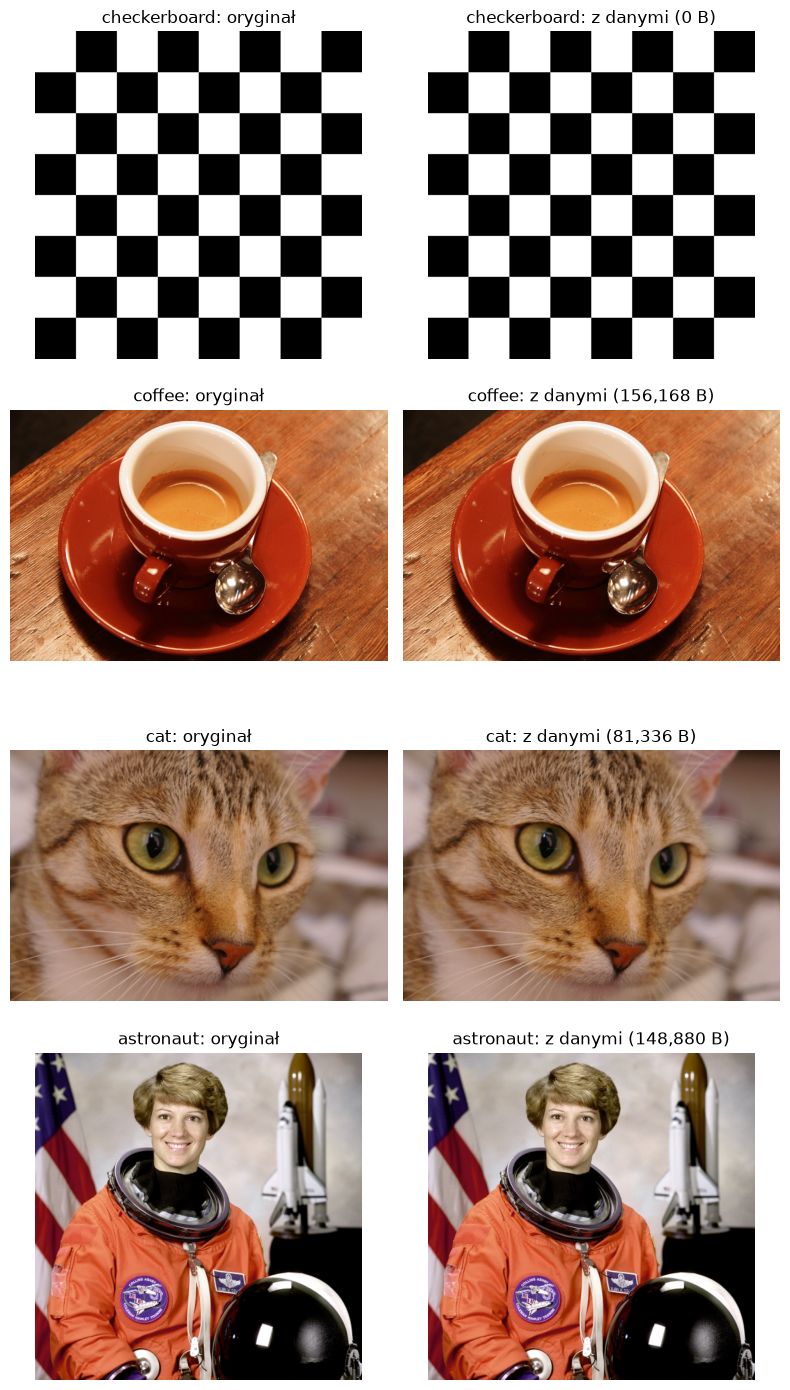

Zły klucz: Brak danych albo zły klucz / próg.


In [ ]:
def psnr(a, b):
    mse = np.mean((a.astype(float) - b.astype(float)) ** 2)
    return np.inf if mse == 0 else 10 * np.log10(255 ** 2 / mse)


KEY, ALPHA0, FILL = 1234, 0.3, 0.5
rng = np.random.default_rng(0)
fig, axes = plt.subplots(len(imgs_color), 2, figsize=(8, 3.5 * len(imgs_color)))

for img, name, (ax_orig, ax_stego) in zip(imgs_color, image_names, axes):
    cap = capacity(img, ALPHA0)
    size = int(cap * FILL) // 8 * 8
    secret = bytearray(rng.bytes(size))
    secret[: size // 10] = bytes(size // 10)  # 10% zer -> proste bloki do sprzężenia
    secret = bytes(secret)

    if cap:
        stego = embed(img, secret, KEY, ALPHA0)
        ok = extract(stego, KEY, ALPHA0) == secret
        n_conj = int((complexity(bytes_to_blocks(secret)) < ALPHA0).sum())
        print(f"{name:12s} pojemność: {cap:>8,d} B ({cap / img.size:5.1%} obrazu), osadzono {size:>8,d} B | sprzężone bloki: {n_conj:>5d} | "
              f"PSNR: {psnr(img, stego):4.1f} dB | odczyt poprawny: {ok}")
    else:
        stego = img
        print(f"{name:12s} pojemność: 0 B - obraz nie ma szumopodobnych bloków")

    ax_orig.imshow(img); ax_orig.set_title(f"{name}: oryginał")
    ax_stego.imshow(stego); ax_stego.set_title(f"{name}: z danymi ({len(secret):,} B)")
    ax_orig.axis("off"); ax_stego.axis("off")

plt.tight_layout()
plt.show()

try: # zły klucz nie ujawnia danych
    extract(stego, KEY + 1, ALPHA0)
except ValueError as e:
    print("Zły klucz:", e)